In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix,classification_report
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier,AdaBoostClassifier
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.svm import SVC
from nltk import word_tokenize
from nltk.stem import WordNetLemmatizer, PorterStemmer
from nltk.corpus import stopwords
import re
import nltk
from nltk import word_tokenize, FreqDist

In [ ]:
import nltk
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('wordnet')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


True

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/Deep Learning/sentiment_data.txt',sep=";",header=None)
df.head()

,0,1
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


In [ ]:
df.shape

(16000, 2)

In [ ]:
df.columns = ['sent','emotions']
df.head(10)

,sent,emotions
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger
5,ive been feeling a little burdened lately wasn...,sadness
6,ive been taking or milligrams or times recomme...,surprise
7,i feel as confused about life as a teenager or...,fear
8,i have been with petronas for years i feel tha...,joy
9,i feel romantic too,love


In [ ]:
df['emotions'].value_counts()

,count
emotions,
joy,5362
sadness,4666
anger,2159
fear,1937
love,1304
surprise,572


In [ ]:
df.isnull().sum()

,0
sent,0
emotions,0


In [ ]:
df.duplicated().sum()

np.int64(1)

In [ ]:
df.drop_duplicates(inplace=True)
df.duplicated().sum()

np.int64(0)

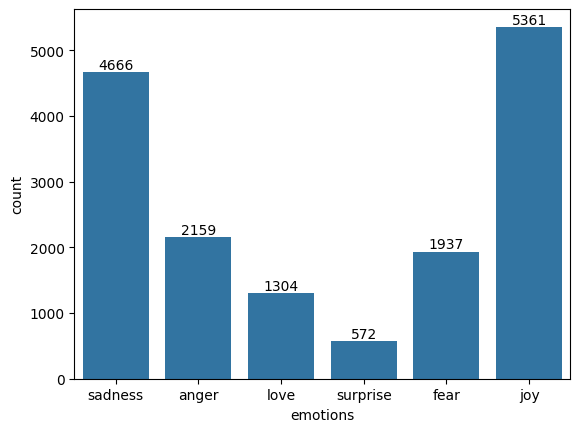

In [ ]:
ax = sns.countplot(data=df,x="emotions")
ax.bar_label(ax.containers[0])
plt.show()


In [ ]:
lm = WordNetLemmatizer()
sw = stopwords.words('english')
print(sw[:8])

['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all']


In [ ]:
df['sent'][:5]

,sent
0,i didnt feel humiliated
1,i can go from feeling so hopeless to so damned...
2,im grabbing a minute to post i feel greedy wrong
3,i am ever feeling nostalgic about the fireplac...
4,i am feeling grouchy


In [ ]:
!pip install text_hammer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.1/115.1 kB 4.3 MB/s eta 0:00:00
  Attempting uninstall: beautifulsoup4
    Found existing installation: beautifulsoup4 4.13.5
    Uninstalling beautifulsoup4-4.13.5:
      Successfully uninstalled beautifulsoup4-4.13.5
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
libpysal 4.14.1 requires beautifulsoup4>=4.13.0, but you have beautifulsoup4 4.9.1 which is incompatible.
yfinance 0.2.66 requires beautifulsoup4>=4.11.1, but you have beautifulsoup4 4.9.1 which is incompatible.
pysal 25.7 requires beautifulsoup4>=4.10, but you have beautifulsoup4 4.9.1 which is incompatible.


In [ ]:
import text_hammer as th

In [ ]:
def text_preprocessing(df,col):
    df[col] = df[col].progress_apply(lambda x: str(x).lower())
    df[col] = df[col].progress_apply(lambda x: th.cont_exp(x))   # you're -> you are; i'm -> i am, i'll -> I will
    df[col] = df[col].progress_apply(lambda x: th.remove_emails(x))
    df[col] = df[col].progress_apply(lambda x: th.remove_html_tags(x))
    df[col] = df[col].progress_apply(lambda x: th.remove_stopwords(x))
    df[col] = df[col].progress_apply(lambda x: th.remove_special_chars(x))
    df[col] = df[col].progress_apply(lambda x: th.make_base(x))        # ran -> run, # make_base - to convert intomits root word
    return(df)

In [ ]:
df = text_preprocessing(df, "sent")

  0%|          | 0/15999 [00:00<?, ?it/s]

  0%|          | 0/15999 [00:00<?, ?it/s]

  0%|          | 0/15999 [00:00<?, ?it/s]

  0%|          | 0/15999 [00:00<?, ?it/s]

  0%|          | 0/15999 [00:00<?, ?it/s]

  0%|          | 0/15999 [00:00<?, ?it/s]

  0%|          | 0/15999 [00:00<?, ?it/s]

In [ ]:
encoded_dict  = {'anger':0,'fear':1, 'joy':2, 'love':3, 'sadness':4, 'surprise':5}

In [ ]:
x = df['sent']
y = df['emotions']
print(x.shape)
print(y.shape)

(15999,)
(15999,)


In [ ]:
df_joy = df[df['emotions']=="joy"]
print(df_joy.shape)
df_sadness = df[df['emotions']=="sadness"]
print(df_sadness.shape)
df_anger = df[df['emotions']=="anger"]
print(df_anger.shape)
df_fear = df[df['emotions']=="fear"]
print(df_fear.shape)
df_love = df[df['emotions']=="love"]
print(df_love.shape)
df_surprise = df[df['emotions']=="surprise"]
print(df_surprise.shape)

(5361, 2)
(4666, 2)
(2159, 2)
(1937, 2)
(1304, 2)
(572, 2)


#### Find Top N Word Freq

In [ ]:
# w = [5,7,9]
# print(w)
# w.append(12)
# print(w)
# w.extend([14,15])
# print(w)

In [ ]:
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [ ]:
# res_sent = []
# for i in df['sent']:
#   w = word_tokenize(i)
#   w = [i for i in w if i not in sw]
#   w = ' '.join(w)
#   res_sent.append(w)
# print(len(res_sent))

15999


In [ ]:
# res_sent[:5]

['feel humiliated',
 'feel hopeless damned hopeful care awake',
 'I grab minute post feel greedy wrong',
 'feel nostalgic fireplace know property',
 'feel grouchy']

In [ ]:
# df1 = pd.DataFrame(res_sent,columns=['sent'])
# df1['emotions'] = df['emotions'].values
# df1.head()

,sent,emotions
0,feel humiliated,sadness
1,feel hopeless damned hopeful care awake,sadness
2,I grab minute post feel greedy wrong,anger
3,feel nostalgic fireplace know property,love
4,feel grouchy,anger


In [ ]:
# df1_joy = df1[df1['emotions']=="joy"]
# print(df1_joy.shape)
# df1_sadness = df1[df1['emotions']=="sadness"]
# print(df1_sadness.shape)
# df1_anger = df1[df1['emotions']=="anger"]
# print(df1_anger.shape)
# df1_fear = df1[df1['emotions']=="fear"]
# print(df1_fear.shape)
# df1_love = df1[df1['emotions']=="love"]
# print(df1_love.shape)
# df1_surprise = df1[df1['emotions']=="surprise"]
# print(df1_surprise.shape)

(5361, 2)
(4666, 2)
(2159, 2)
(1937, 2)
(1304, 2)
(572, 2)


In [ ]:
def find_topN_word_freq_4each_emotion(data,word_list):
  for i in data['sent']:
    word_list.extend(word_tokenize(i))
  freq_dist = FreqDist(word_list).most_common(100)
  return freq_dist

In [ ]:
wt_joy = []
freq_dist_joy = find_topN_word_freq_4each_emotion(df_joy, wt_joy)
print(freq_dist_joy)

[('feel', 5425), ('like', 1014), ('m', 939), ('I', 821), ('not', 451), ('time', 329), ('feeling', 312), ('s', 303), ('know', 286), ('want', 266), ('t', 259), ('think', 253), ('day', 241), ('love', 238), ('do', 233), ('go', 231), ('good', 229), ('people', 206), ('life', 196), ('thing', 194), ('little', 189), ('need', 187), ('pretty', 184), ('get', 179), ('work', 175), ('look', 170), ('way', 161), ('come', 153), ('happy', 152), ('make', 148), ('year', 134), ('right', 124), ('try', 120), ('today', 119), ('find', 118), ('help', 115), ('don', 114), ('sure', 110), ('well', 108), ('write', 102), ('tell', 97), ('leave', 97), ('say', 94), ('have', 94), ('bit', 91), ('start', 90), ('important', 87), ('read', 87), ('friend', 86), ('long', 85), ('support', 83), ('lot', 82), ('glad', 81), ('content', 81), ('cool', 80), ('free', 80), ('able', 78), ('thankful', 78), ('new', 77), ('safe', 75), ('excited', 75), ('family', 75), ('strong', 75), ('http', 74), ('live', 74), ('can', 74), ('week', 73), ('con

In [ ]:
wt_sadness =[]
freq_dist_sadness = find_topN_word_freq_4each_emotion(df_sadness,wt_sadness)
print(freq_dist_sadness)

[('feel', 4697), ('like', 874), ('m', 796), ('I', 703), ('not', 535), ('feeling', 370), ('know', 323), ('do', 276), ('t', 272), ('time', 268), ('want', 237), ('think', 225), ('day', 224), ('thing', 221), ('little', 194), ('go', 192), ('s', 187), ('life', 181), ('people', 180), ('bit', 170), ('way', 144), ('love', 136), ('need', 135), ('try', 132), ('work', 131), ('good', 126), ('start', 124), ('pretty', 121), ('don', 120), ('get', 120), ('leave', 115), ('come', 114), ('look', 113), ('bad', 113), ('right', 111), ('can', 109), ('friend', 108), ('today', 107), ('make', 102), ('miss', 101), ('year', 96), ('week', 96), ('find', 91), ('have', 91), ('help', 89), ('lot', 87), ('kind', 81), ('hurt', 81), ('stupid', 78), ('home', 77), ('tell', 77), ('low', 76), ('sad', 75), ('lose', 75), ('sorry', 75), ('ache', 74), ('miserable', 73), ('say', 72), ('away', 70), ('pain', 70), ('guilty', 69), ('awkward', 68), ('lethargic', 67), ('http', 67), ('depressed', 67), ('ashamed', 66), ('write', 66), ('exh

In [ ]:
wt_anger =[]
freq_dist_anger = find_topN_word_freq_4each_emotion(df_anger,wt_anger)
print(freq_dist_anger)

[('feel', 2151), ('m', 420), ('like', 391), ('I', 356), ('not', 269), ('t', 143), ('feeling', 138), ('time', 137), ('know', 135), ('want', 130), ('do', 124), ('think', 110), ('thing', 109), ('people', 106), ('little', 105), ('s', 104), ('way', 92), ('get', 87), ('angry', 85), ('go', 82), ('bit', 77), ('day', 76), ('life', 74), ('irritable', 70), ('cold', 68), ('don', 68), ('fuck', 67), ('need', 66), ('friend', 66), ('come', 64), ('can', 64), ('greedy', 63), ('try', 63), ('start', 61), ('resentful', 60), ('selfish', 59), ('wrong', 58), ('irritated', 57), ('love', 56), ('violent', 55), ('cranky', 55), ('mad', 55), ('dissatisfied', 54), ('dangerous', 54), ('rude', 53), ('hat', 53), ('work', 53), ('bother', 53), ('frustrated', 52), ('rush', 52), ('annoyed', 52), ('jealous', 51), ('say', 50), ('bitchy', 50), ('agitated', 50), ('make', 50), ('right', 49), ('bitter', 48), ('good', 48), ('today', 47), ('petty', 46), ('rebellious', 45), ('offended', 44), ('disgusted', 42), ('impatient', 42), ('

In [ ]:
wt_fear =[]
freq_dist_fear = find_topN_word_freq_4each_emotion(df_fear,wt_fear)
print(freq_dist_fear)

[('feel', 1942), ('m', 379), ('I', 329), ('like', 261), ('not', 179), ('little', 149), ('know', 148), ('feeling', 125), ('t', 123), ('bit', 117), ('time', 108), ('want', 106), ('do', 102), ('think', 98), ('people', 91), ('go', 91), ('s', 87), ('thing', 85), ('strange', 78), ('nervous', 75), ('start', 71), ('anxious', 71), ('day', 68), ('afraid', 68), ('way', 66), ('unsure', 64), ('vulnerable', 64), ('weird', 61), ('uncertain', 61), ('scared', 60), ('reluctant', 59), ('apprehensive', 58), ('terrified', 57), ('overwhelmed', 56), ('pressured', 55), ('paranoid', 55), ('insecure', 55), ('life', 54), ('come', 53), ('get', 53), ('shake', 52), ('need', 52), ('intimidate', 52), ('make', 52), ('work', 50), ('love', 50), ('hesitant', 50), ('leave', 50), ('shy', 49), ('agitated', 49), ('uncomfortable', 48), ('find', 48), ('shaky', 48), ('helpless', 47), ('help', 46), ('write', 46), ('fearful', 44), ('don', 43), ('right', 43), ('look', 43), ('try', 43), ('tell', 39), ('talk', 39), ('frantic', 37), 

In [ ]:
wt_love =[]
freq_dist_love = find_topN_word_freq_4each_emotion(df_love,wt_love)
print(freq_dist_love)

[('feel', 1303), ('like', 364), ('m', 226), ('love', 199), ('I', 197), ('not', 123), ('feeling', 122), ('know', 97), ('want', 88), ('time', 83), ('s', 78), ('t', 75), ('sweet', 69), ('think', 68), ('need', 65), ('care', 65), ('passionate', 63), ('do', 63), ('life', 60), ('people', 57), ('hot', 56), ('little', 55), ('support', 55), ('sympathetic', 55), ('lovely', 55), ('nostalgic', 48), ('go', 48), ('naughty', 47), ('way', 47), ('supportive', 46), ('horny', 46), ('day', 46), ('gentle', 44), ('loyal', 44), ('long', 43), ('tender', 43), ('romantic', 42), ('accept', 41), ('fond', 40), ('get', 40), ('generous', 40), ('thing', 40), ('friend', 39), ('delicate', 38), ('try', 37), ('blessed', 35), ('longing', 35), ('don', 35), ('start', 34), ('bit', 34), ('good', 33), ('look', 32), ('have', 31), ('beloved', 29), ('let', 28), ('god', 28), ('work', 28), ('faithful', 27), ('tell', 27), ('family', 27), ('come', 26), ('year', 26), ('live', 26), ('find', 25), ('make', 24), ('can', 24), ('help', 24), 

In [ ]:
wt_surprise =[]
freq_dist_surprise = find_topN_word_freq_4each_emotion(df_surprise,wt_surprise)
print(freq_dist_surprise)

[('feel', 552), ('m', 116), ('I', 92), ('like', 90), ('amazed', 65), ('overwhelmed', 58), ('weird', 57), ('curious', 54), ('feeling', 54), ('not', 50), ('funny', 49), ('surprised', 49), ('impressed', 48), ('strange', 45), ('little', 44), ('time', 41), ('amazing', 40), ('s', 35), ('know', 32), ('think', 32), ('shocked', 31), ('people', 30), ('bit', 30), ('daze', 30), ('do', 28), ('find', 28), ('remember', 26), ('t', 25), ('life', 23), ('thing', 23), ('go', 22), ('look', 22), ('way', 21), ('day', 20), ('make', 20), ('love', 20), ('work', 18), ('actually', 18), ('read', 17), ('come', 17), ('get', 17), ('start', 16), ('want', 16), ('pretty', 16), ('stunned', 15), ('say', 15), ('year', 15), ('need', 15), ('shock', 15), ('new', 14), ('tell', 14), ('good', 14), ('impress', 14), ('friend', 13), ('try', 13), ('book', 13), ('don', 13), ('see', 12), ('hear', 12), ('sit', 12), ('leave', 11), ('sure', 11), ('family', 11), ('help', 11), ('world', 11), ('today', 11), ('long', 11), ('wake', 10), ('d',

In [ ]:
print(type(freq_dist_joy))

<class 'list'>


In [ ]:
from wordcloud import WordCloud

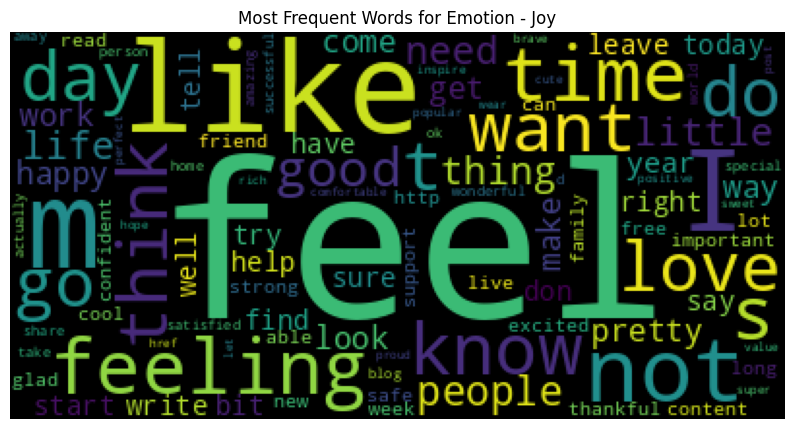

In [ ]:
joy = WordCloud().generate_from_frequencies(dict(freq_dist_joy))
plt.figure(figsize=(10,10))
plt.title('Most Frequent Words for Emotion - Joy')
plt.imshow(joy)
plt.axis('off')
plt.show()

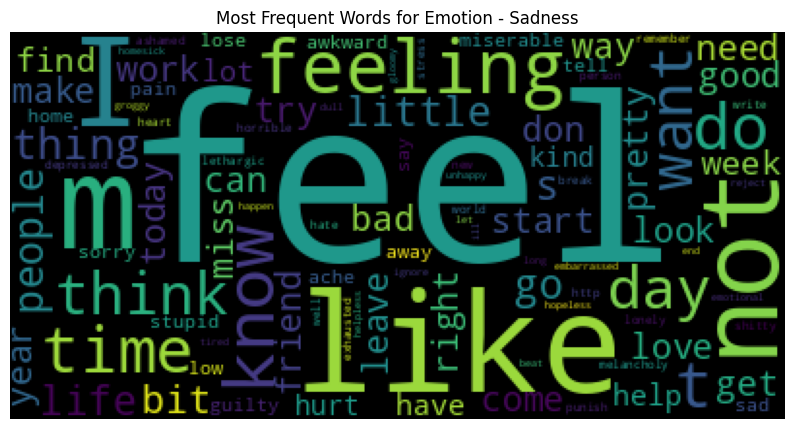

In [ ]:
sadness = WordCloud().generate_from_frequencies(dict(freq_dist_sadness))
plt.figure(figsize=(10,10))
plt.title('Most Frequent Words for Emotion - Sadness')
plt.imshow(sadness)
plt.axis('off')
plt.show()

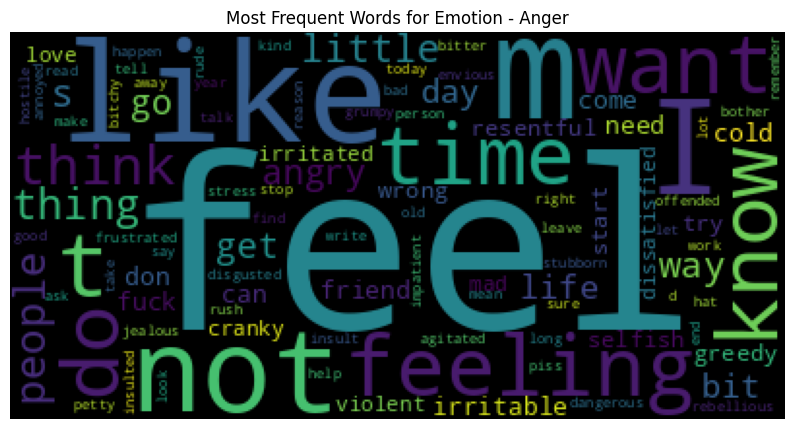

In [ ]:
anger = WordCloud().generate_from_frequencies(dict(freq_dist_anger))
plt.figure(figsize=(10,10))
plt.title('Most Frequent Words for Emotion - Anger')
plt.imshow(anger)
plt.axis('off')
plt.show()

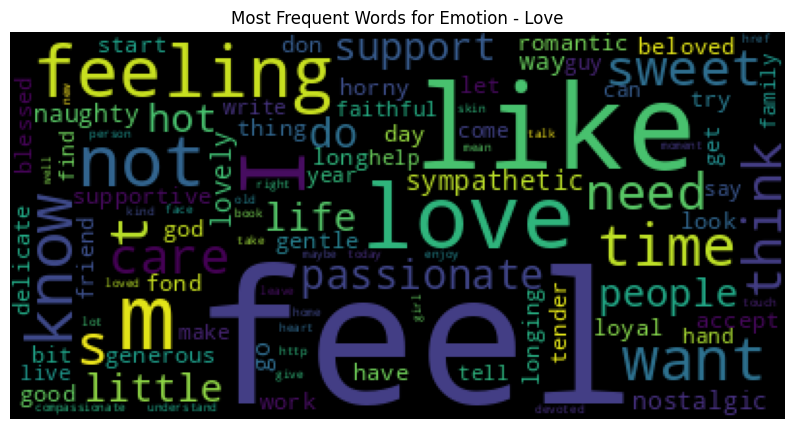

In [ ]:
love = WordCloud().generate_from_frequencies(dict(freq_dist_love))
plt.figure(figsize=(10,10))
plt.title('Most Frequent Words for Emotion - Love')
plt.imshow(love)
plt.axis('off')
plt.show()

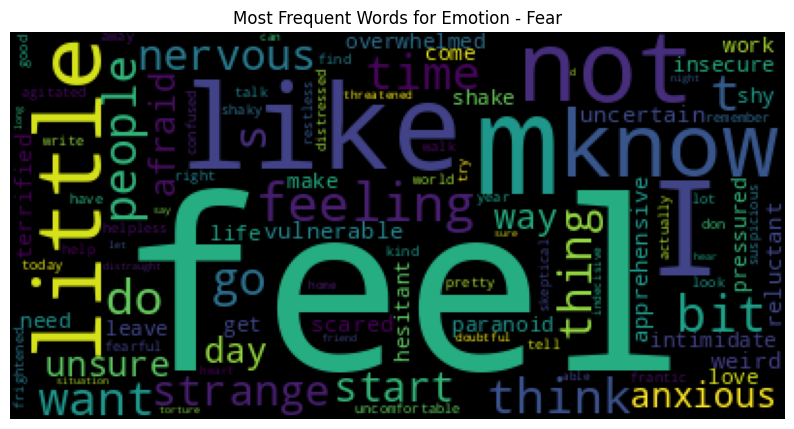

In [ ]:
fear = WordCloud().generate_from_frequencies(dict(freq_dist_fear))
plt.figure(figsize=(10,10))
plt.title('Most Frequent Words for Emotion - Fear')
plt.imshow(fear)
plt.axis('off')
plt.show()

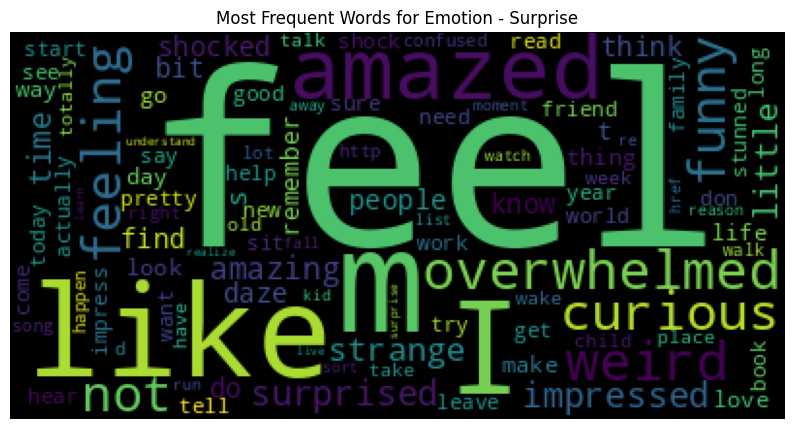

In [ ]:
surprise = WordCloud().generate_from_frequencies(dict(freq_dist_surprise))
plt.figure(figsize=(10,10))
plt.title('Most Frequent Words for Emotion - Surprise')
plt.imshow(surprise)
plt.axis('off')
plt.show()

In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [ ]:
x = df['sent']
y = df['emotions']
print(x.shape)
print(y.shape)

(15999,)
(15999,)


In [ ]:
df.head()

,sent,emotions
0,do not feel humiliated,sadness
1,feel hopeless damned hopeful care awake,sadness
2,I m grab minute post feel greedy wrong,anger
3,feel nostalgic fireplace know property,love
4,feel grouchy,anger


In [ ]:
max_words = 30000  # assumed estimate

tk = Tokenizer(num_words=max_words)
tk.fit_on_texts(x)

word_index = tk.word_index
print(len(word_index))
print("Word index:\n", word_index)

12079
Word index:
 {'feel': 1, 'like': 2, 'm': 3, 'i': 4, 'not': 5, 'feeling': 6, 'know': 7, 'time': 8, 't': 9, 'want': 10, 'do': 11, 's': 12, 'think': 13, 'little': 14, 'love': 15, 'day': 16, 'thing': 17, 'people': 18, 'go': 19, 'life': 20, 'way': 21, 'need': 22, 'bit': 23, 'get': 24, 'good': 25, 'work': 26, 'come': 27, 'look': 28, 'try': 29, 'start': 30, 'make': 31, 'pretty': 32, 'don': 33, 'right': 34, 'find': 35, 'friend': 36, 'year': 37, 'today': 38, 'leave': 39, 'help': 40, 'can': 41, 'tell': 42, 'have': 43, 'say': 44, 'write': 45, 'lot': 46, 'long': 47, 'happy': 48, 'well': 49, 'week': 50, 'sure': 51, 'kind': 52, 'away': 53, 'home': 54, 'read': 55, 'person': 56, 'let': 57, 'd': 58, 'remember': 59, 'talk': 60, 'world': 61, 'actually': 62, 'new': 63, 'take': 64, 'bad': 65, 'end': 66, 'family': 67, 'http': 68, 'moment': 69, 'post': 70, 'miss': 71, 'care': 72, 'live': 73, 'mean': 74, 'able': 75, 'happen': 76, 'lose': 77, 'support': 78, 'child': 79, 'place': 80, 'run': 81, 'stop': 82

In [ ]:
print('\nWord Count in Doc\n',tk.word_counts)


Word Count in Doc
 OrderedDict({'do': 826, 'not': 1607, 'feel': 16070, 'humiliated': 18, 'hopeless': 65, 'damned': 4, 'hopeful': 59, 'care': 178, 'awake': 23, 'i': 2561, 'm': 2876, 'grab': 16, 'minute': 64, 'post': 180, 'greedy': 65, 'wrong': 113, 'nostalgic': 51, 'fireplace': 3, 'know': 1021, 'property': 4, 'grouchy': 27, 'little': 736, 'burden': 54, 'lately': 98, 'was': 95, 'sure': 232, 'take': 202, 'milligram': 1, 'times': 12, 'recommend': 14, 'fall': 80, 'asleep': 18, 'lot': 264, 'fast': 28, 'like': 2994, 'funny': 69, 'confused': 54, 'life': 588, 'teenager': 19, 'jade': 42, 'year': 336, 'old': 151, 'man': 127, 'petronas': 1, 'petrona': 1, 'perform': 12, 'huge': 28, 'profit': 5, 'romantic': 51, 'suffering': 16, 'see': 138, 'mean': 175, 'run': 164, 'divine': 61, 'experience': 114, 'expect': 68, 'type': 54, 'spiritual': 11, 'encounter': 8, 'think': 786, 's': 794, 'easy': 54, 'time': 966, 'dissatisfied': 55, 'low': 100, 'energy': 71, 'thirsty': 3, 'immense': 3, 'sympathy': 14, 'genera

In [ ]:
sequences = tk.texts_to_sequences(x)
print("Training sequences:\n", sequences)

Training sequences:
 [[11, 5, 1, 1125], [1, 326, 2855, 363, 72, 949], [4, 3, 1215, 334, 70, 1, 327, 148], [1, 473, 3374, 7, 2856], [1, 833], [1, 14, 434, 186, 189, 5, 51], [64, 5834, 1467, 1328, 238, 1126, 46, 809, 1, 2, 295], [1, 435, 20, 1082, 584, 37, 94, 127], [5835, 37, 1, 5836, 1468, 810, 2520], [1, 474], [1, 2, 1216, 3, 109, 74], [1, 81, 350, 145, 302, 436, 1553, 1924], [13, 12, 437, 8, 37, 1, 419], [1, 184, 285, 3, 3375], [3376, 1329, 769, 98, 675, 5837, 861, 29, 35, 8, 45, 1330, 20, 1050, 2857, 57, 2521, 2069, 1, 14, 335], [1, 1658, 791], [11, 5, 1, 303], [1, 32, 420, 8], [30, 1, 676, 2070, 79, 118, 1554, 1775, 3377, 2070, 5838], [1, 5839, 677, 251, 2858, 26], [1, 336, 337, 44], [1, 146, 114, 1925, 40, 1, 4195, 1776, 85, 1331, 1051, 834, 90, 66, 402, 17, 542], [1, 950, 835], [75, 40, 5840, 4196, 78, 2859, 130, 6, 194, 75, 40], [1, 2, 172, 11, 5, 281, 111, 102], [15, 162, 49, 47, 1926, 718, 5841, 5842, 167, 174, 438, 132, 56, 216, 52, 18, 1, 123], [1, 951, 1927, 1217, 2, 4, 3, 

In [ ]:
# Get max training sequence length
max_len = max([len(x) for x in sequences])
print('Max training sequence length',max_len)

Max training sequence length 36


In [ ]:
x_pad = pad_sequences(sequences, maxlen=max_len)  # padding = 'pre', 'post' zeros on start (pre)[0,0,11, 5, 1, 1125], end(post)[11, 5, 1, 1125,0,0]
print(len(x_pad))
print('Padded_sequences\n',x_pad)

15999
Padded_sequences
 [[   0    0    0 ...    5    1 1125]
 [   0    0    0 ...  363   72  949]
 [   0    0    0 ...    1  327  148]
 ...
 [   0    0    0 ...  160   25 1080]
 [   0    0    0 ...    3  194    9]
 [   0    0    0 ...    1  143 2125]]


In [ ]:
print(x_pad.shape)

(15999, 36)


In [ ]:
from sklearn.preprocessing import LabelEncoder
lb = LabelEncoder()

In [ ]:
df['emotions'].value_counts()

,count
emotions,
joy,5361
sadness,4666
anger,2159
fear,1937
love,1304
surprise,572


In [ ]:
y_lab = lb.fit_transform(y)
from collections import Counter
print(Counter(y_lab))

Counter({np.int64(2): 5361, np.int64(4): 4666, np.int64(0): 2159, np.int64(1): 1937, np.int64(3): 1304, np.int64(5): 572})


In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
x_train,x_test,y_train,y_test = train_test_split(x_pad,y_lab,test_size=0.30,random_state=42)
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(11199, 36)
(4800, 36)
(11199,)
(4800,)


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Embedding, Flatten
import tensorflow as tf
from tensorflow.keras.layers import Dropout
from tensorflow.keras.callbacks import EarlyStopping

In [ ]:
vocab_size = max_words + 1
embedding_dim = 64
print(vocab_size)
print(embedding_dim)
print(x_pad.shape)
print(x_pad.shape[1])

# Embedding(vocab_size,embedding_dim,36)

# small datasets - 0-100
# large datasets - 100-200+

30001
64
(15999, 36)
36


In [ ]:
m1 = Sequential()
#                 (30001)     , (64)          , (36)
m1.add(Embedding(vocab_size, embedding_dim, input_length=x_pad.shape[1]))
m1.add(LSTM(200, return_sequences=True))  # 33*64 is used as input for LSTM
m1.add(Dropout(0.5))
m1.add(LSTM(200))                         # by default return sequence id False
m1.add(Dropout(0.5))
m1.add(Dense(128,activation='relu'))
m1.add(Dropout(0.5))
m1.add(Dense(6,activation='softmax'))
                 # cuz target variable is label encoded
m1.compile(loss='sparse_categorical_crossentropy',optimizer='adam',metrics=['acc'])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [ ]:
h1 = m1.fit(x_train,y_train,validation_data=(x_test,y_test),batch_size=64,epochs=10)

Epoch 1/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 11s 19ms/step - acc: 0.3496 - loss: 1.5540 - val_acc: 0.4835 - val_loss: 1.2571
Epoch 2/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - acc: 0.6993 - loss: 0.8073 - val_acc: 0.8142 - val_loss: 0.5210
Epoch 3/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - acc: 0.8929 - loss: 0.3182 - val_acc: 0.8817 - val_loss: 0.3558
Epoch 4/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - acc: 0.9431 - loss: 0.1702 - val_acc: 0.8829 - val_loss: 0.3758
Epoch 5/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - acc: 0.9560 - loss: 0.1321 - val_acc: 0.8842 - val_loss: 0.3888
Epoch 6/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - acc: 0.9671 - loss: 0.1043 - val_acc: 0.8904 - val_loss: 0.4159
Epoch 7/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - acc: 0.9726 - loss: 0.0873 - val_acc: 0.8827 - val_loss: 0.4311
Epoch 8/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - acc: 0.9755 - loss: 0.0773 - val_acc: 0.8817 - val_loss: 0.5309
Epoch 9/10
175/175 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms

In [ ]:
r1 = pd.DataFrame(h1.history)
r1['Epochs'] = h1.epoch
r1.head(10)

,acc,loss,val_acc,val_loss,Epochs
0,0.349585,1.554040,0.483542,1.257136,0
1,0.699259,0.807264,0.814167,0.520991,1
2,0.892937,0.318225,0.881667,0.355814,2
3,0.943120,0.170222,0.882917,0.375770,3
4,0.955978,0.132145,0.884167,0.388820,4
5,0.967051,0.104272,0.890417,0.415897,5
6,0.972587,0.087332,0.882708,0.431058,6
7,0.975534,0.077349,0.881667,0.530945,7
8,0.980980,0.057540,0.878958,0.562662,8
9,0.980534,0.062335,0.874375,0.568276,9


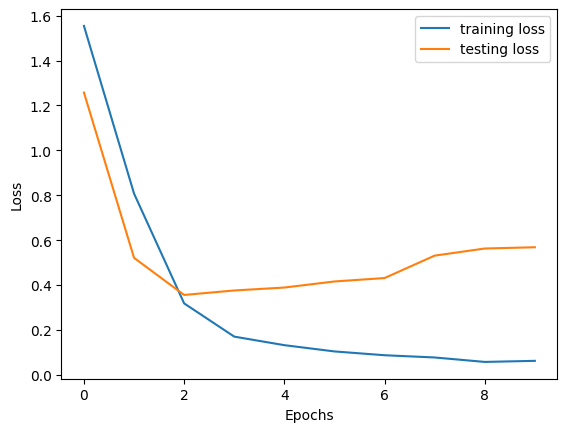

In [ ]:
plt.plot(r1['Epochs'],r1['loss'],label='training loss')
plt.plot(r1['Epochs'],r1['val_loss'],label='testing loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

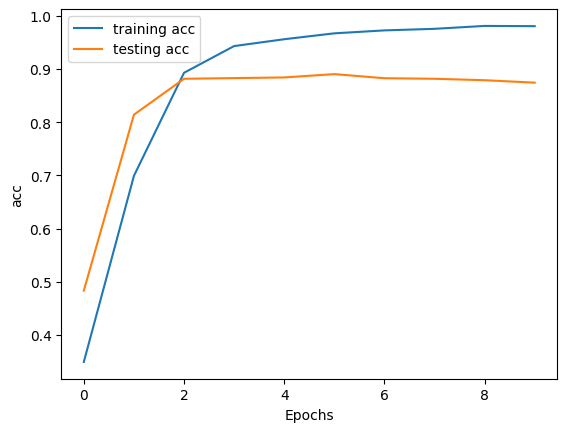

In [ ]:
plt.plot(r1['Epochs'],r1['acc'],label='training acc')
plt.plot(r1['Epochs'],r1['val_acc'],label='testing acc')
plt.xlabel('Epochs')
plt.ylabel('acc')
plt.legend()
plt.show()

In [ ]:
ypred = m1.predict(x_test)
print(ypred[:5])

150/150 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step
[[9.9473524e-05 6.7226606e-06 2.9081044e-05 6.7305059e-08 9.9986458e-01
  1.4896024e-09]
 [2.3707378e-10 1.8025169e-10 9.9998999e-01 4.9697237e-06 4.9532296e-06
  7.4492225e-11]
 [2.8751791e-07 9.3045387e-08 1.5018132e-07 1.7640391e-10 9.9999952e-01
  4.1547512e-12]
 [1.1164755e-08 4.0931991e-09 9.9996102e-01 2.8742572e-05 1.0280998e-05
  1.9860353e-09]
 [2.6301018e-07 2.0331228e-08 2.8868089e-07 4.9323955e-11 9.9999940e-01
  2.1756989e-13]]


In [ ]:
ypred_lab = [np.argmax(i) for i in ypred]
print(ypred_lab[:10])

[np.int64(4), np.int64(2), np.int64(4), np.int64(2), np.int64(4), np.int64(2), np.int64(1), np.int64(4), np.int64(2), np.int64(1)]


In [ ]:
from sklearn.metrics import *

In [ ]:
cm = confusion_matrix(y_test,ypred_lab)
print(cm)
print(classification_report(y_test,ypred_lab))

[[ 528   40   11    8   34    1]
 [  11  464    9    2   25   29]
 [  20    6 1487   55   24    7]
 [  12    4  124  287   10    1]
 [  37   27   68   12 1293    4]
 [   0   14    5    2    1  138]]
              precision    recall  f1-score   support

           0       0.87      0.85      0.86       622
           1       0.84      0.86      0.85       540
           2       0.87      0.93      0.90      1599
           3       0.78      0.66      0.71       438
           4       0.93      0.90      0.91      1441
           5       0.77      0.86      0.81       160

    accuracy                           0.87      4800
   macro avg       0.84      0.84      0.84      4800
weighted avg       0.87      0.87      0.87      4800



In [ ]:
# joy         5361  # 2
# sadness     4666  # 4
# anger       2159  # 0
# fear        1937  # 1
# love        1304  # 3
# surprise     572  # 5
Counter(y_lab)

Counter({np.int64(4): 4666,
         np.int64(0): 2159,
         np.int64(3): 1304,
         np.int64(5): 572,
         np.int64(1): 1937,
         np.int64(2): 5361})

#### Custom test data

In [ ]:
ctest_df = pd.DataFrame({'sent':['I love solo travelling',
                                  'Delighted to start my new job',
                                  'Hard Challenges bringing my morale down',
                                  'Her absence was painful',
                                  'His presence annoys me',
                                  'I was scared of the darkness',
                                  'I was astonished after receiving the gift',
                                  'I heard a strange sound',
                                  'It suddenly started raining today',
                                  'I was amazed by the science marks',
                                   'food was lovely']})

ctest_df

,sent
0,I love solo travelling
1,Delighted to start my new job
2,Hard Challenges bringing my morale down
3,Her absence was painful
4,His presence annoys me
5,I was scared of the darkness
6,I was astonished after receiving the gift
7,I heard a strange sound
8,It suddenly started raining today
9,I was amazed by the science marks


In [ ]:
def map_lab_2emotions(data):
    res = []
    d = {0:'anger',1:'fear',2:'joy',3:'love',4:'sadness',5:'surpise'}
    for i in data:
        if i in d.keys():
            res.append(d[i])
    return res

In [ ]:
tokens = tk.texts_to_sequences(ctest_df['sent'])

test_sent = pad_sequences(tokens, maxlen=max_len)  # 36
print(test_sent.shape)

# Predict Emotions
emotions = m1.predict(test_sent)
print(emotions)  # prob

# Convert Prob to Predictions
emotions_test = [np.argmax(i) for i in emotions]
print(emotions_test)

(11, 36)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
[[6.8285607e-02 1.4026937e-02 4.3318453e-01 4.3896908e-01 3.2459777e-02
  1.3074049e-02]
 [8.2848576e-04 2.5813284e-04 9.7087169e-01 4.8712105e-03 2.3079881e-02
  9.0478272e-05]
 [6.1936146e-01 8.6685359e-02 5.6516468e-03 5.3228079e-03 2.8107598e-01
  1.9027281e-03]
 [8.6878948e-03 1.9193010e-03 2.5556864e-02 4.3934240e-04 9.6336192e-01
  3.4695913e-05]
 [6.7157716e-01 6.9806509e-02 3.4538087e-02 3.4870230e-02 1.8269828e-01
  6.5096891e-03]
 [4.0531568e-02 8.8315713e-01 9.2240935e-04 6.0741260e-04 6.7523673e-02
  7.2578206e-03]
 [5.5757904e-01 7.1730822e-02 4.5372214e-02 2.8775133e-02 2.9061574e-01
  5.9271050e-03]
 [2.0085683e-02 6.4801925e-01 7.0709861e-03 1.0006521e-02 1.0110736e-02
  3.0470684e-01]
 [3.7930971e-01 1.5108724e-02 8.0893636e-02 1.7958539e-02 5.0593293e-01
  7.9645019e-04]
 [4.3248301e-04 9.8420717e-02 6.5688938e-03 4.5836498e-03 8.3419273e-04
  8.8916004e-01]
 [7.0302509e-02 3.3722988e-03 4.1314222e-02 8.7297112e-01 2.011

In [ ]:
pred_emotions = map_lab_2emotions(emotions_test)
print(pred_emotions)

['love', 'joy', 'anger', 'sadness', 'anger', 'fear', 'anger', 'fear', 'sadness', 'surpise', 'love']


In [ ]:
ctest_df['pred_emotions'] = pred_emotions
ctest_df

,sent,pred_emotions
0,I love solo travelling,love
1,Delighted to start my new job,joy
2,Hard Challenges bringing my morale down,anger
3,Her absence was painful,sadness
4,His presence annoys me,anger
5,I was scared of the darkness,fear
6,I was astonished after receiving the gift,anger
7,I heard a strange sound,fear
8,It suddenly started raining today,sadness
9,I was amazed by the science marks,surpise


In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

In [ ]:
es = EarlyStopping(monitor='val_loss',patience=5)

In [ ]:
m2 = Sequential()
#                 (30001)     , (64)          , (33)
m2.add(Embedding(vocab_size, embedding_dim, input_length=x_pad.shape[1]))
m2.add(LSTM(200, return_sequences=True))  # 36*64 is used as input for LSTM
m2.add(Dropout(0.5))
m2.add(LSTM(200))
m2.add(Dropout(0.5))
m2.add(Dense(128,activation='relu'))
m2.add(Dropout(0.5))
m2.add(Dense(6,activation='softmax'))

m2.compile(loss='sparse_categorical_crossentropy',optimizer='adam',metrics=['acc'])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [ ]:
r2 = m2.fit(x_train,y_train,validation_data=(x_test,y_test),epochs=40,callbacks=[es])

Epoch 1/40
350/350 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - acc: 0.7915 - loss: 0.5908 - val_acc: 0.8558 - val_loss: 0.4003
Epoch 2/40
350/350 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - acc: 0.9092 - loss: 0.2825 - val_acc: 0.8979 - val_loss: 0.2860
Epoch 3/40
350/350 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - acc: 0.9457 - loss: 0.1602 - val_acc: 0.9004 - val_loss: 0.2955
Epoch 4/40
350/350 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step - acc: 0.9570 - loss: 0.1226 - val_acc: 0.9050 - val_loss: 0.2884
Epoch 5/40
350/350 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - acc: 0.9676 - loss: 0.0993 - val_acc: 0.8967 - val_loss: 0.3271
Epoch 6/40
350/350 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - acc: 0.9731 - loss: 0.0806 - val_acc: 0.8946 - val_loss: 0.4493
Epoch 7/40
350/350 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - acc: 0.9741 - loss: 0.0739 - val_acc: 0.8950 - val_loss: 0.3993
